<a href="https://colab.research.google.com/github/anayamgreen/A04-clustering/blob/main/A04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Anaya Green

**Date:** 10/14/2026

Q1

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

The clusters visibly spread out more as the noise value increases. Therefore at level 2.0 the noise has the most amount of spread and the noise level of 0.125 has the least amount of noise.

3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

A factor that I noticed while looking at the scree plots is that the higher the noise level, the less clear the elbow becomes. The most significant drop for all of the graphs is in the k = 1 to k = 3 range, and any number of groups after that has a smaller reduction as k increases. At the higher noise levels, the curves level out more gradually, making the elbow less clear and making it harder to definitively select k. Based on the line graphs, I would select k = 3, although this selection becomes less obvious as the noise increases.

4. Explain the intuition of the elbow, using this numerical simulation as an example.


The intuition of the elbow is that as we increase k, the SSE will decrease because there are more clusters to fit the data. In this simulation, there are three main groups, so going from 1 to 3 clusters causes a large decrease in SSE because the model is better separating into the original groups. After k = 3, adding more clusters still decreases SSE, but by a reuced amount because the three main groups have already been placed into their groups. This is what creates the elbow effect of the plot.





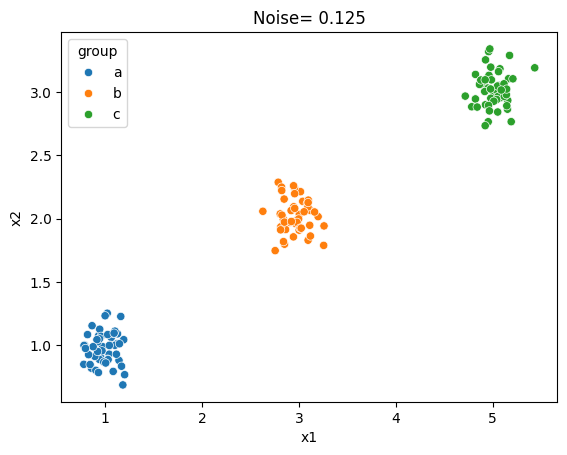

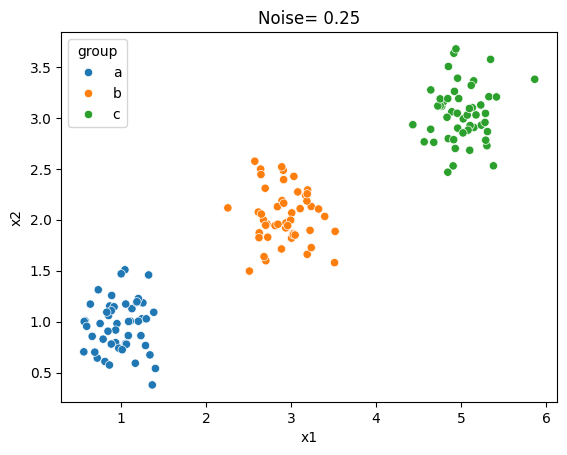

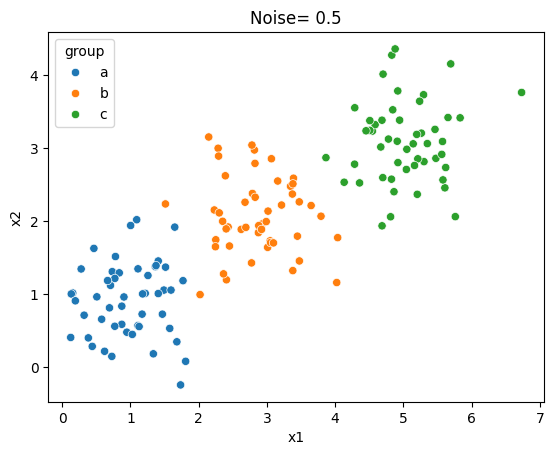

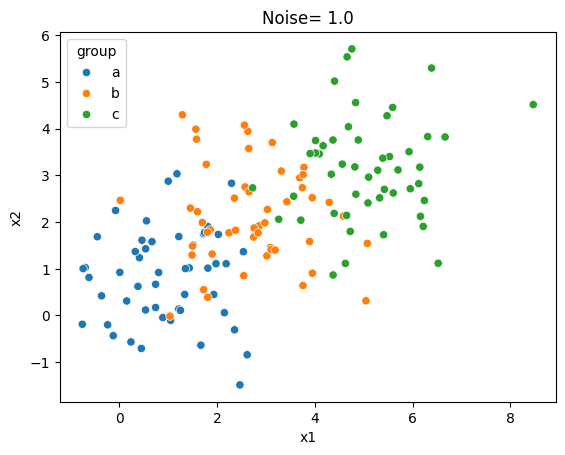

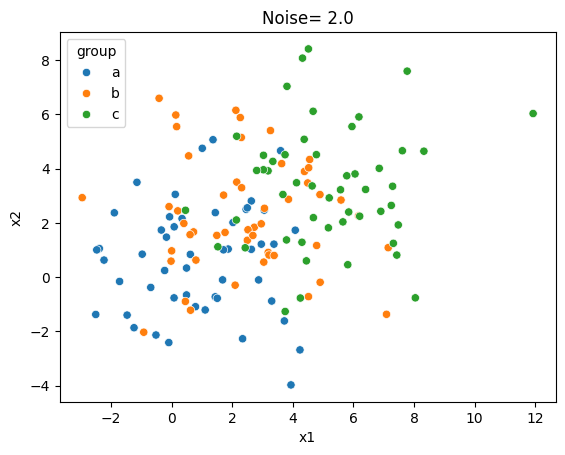

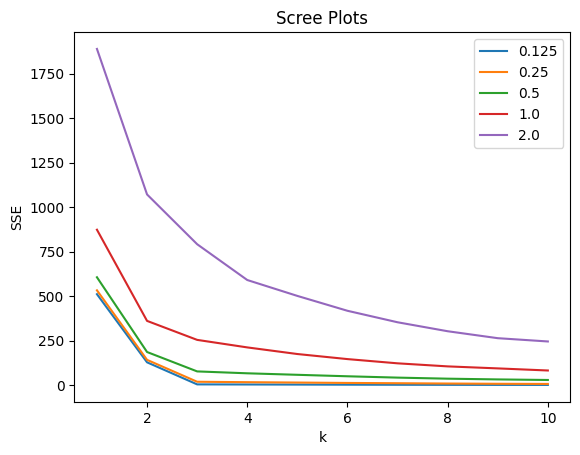

In [ ]:
# Load in data
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


# Scatter plots:
# Noise = 0.125
fig, ax = plt.subplots() # making multiple plots
sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group", ax=ax) # making the scatter plot
ax.set_title("Noise= 0.125") # setting a title
plt.show() # showing the plot
#0.25
fig, ax = plt.subplots() # making multiple plots
sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group", ax=ax)# making the scatter plot
ax.set_title("Noise= 0.25")# setting a title
plt.show()# showing the plot

#0.5
fig, ax = plt.subplots()# making multiple plots
sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group", ax=ax)# making the scatter plot
ax.set_title("Noise= 0.5")# setting a title
plt.show()# showing the plot

#1.0
fig, ax = plt.subplots()# making multiple plots
sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group", ax=ax)# making the scatter plot
ax.set_title("Noise= 1.0")# setting a title
plt.show()# showing the plot

#2.0
fig, ax = plt.subplots() # making multiple plots
sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group", ax=ax)# making the scatter plot
ax.set_title("Noise= 2.0")# setting a title
plt.show()# showing the plot


#Scree plot .125

# making a dictionary for easier referal
dataset = {
    "0.125": df0_125,
    "0.25": df0_25,
    "0.5": df0_5,
    "1.0": df1_0,
    "2.0": df2_0

}

# print(dataset)

# Scree
# example set
# X = df0_125[["x1","x2"]]
ks = np.arange(1, 11) # setting variable ks
# SSE = [
#     KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
#     .fit(X).inertia_
#     for k in ks
# ]
# sns.lineplot(x=ks, y=SSE).set(title="Scree  0.125", xlabel="k", ylabel="SSE")

# making a for loop to run  each level to make a scree plot
for name, df in dataset.items():

    X = df[["x1", "x2"]]# seting variable X

    SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
    ]#calculating the SSE
    sns.lineplot(x=ks, y=SSE, label=name)# making the scree plot

plt.title("Scree Plots")# making a title
plt.xlabel("k") # making x value title
plt.ylabel("SSE") # making y value title
plt.legend()# creating legend
plt.show() # showing the plots




*Q2. This question is a case study on clustering.*

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

For this cluster the United States is resulted as an outlier. The main pattern is that the values are all clustered near 0 on the x-axis, which having different values on the y-axis. The USA, however, is the only point that is at 800000 on the x-axis making it an outlier.

3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?



4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

var.dtypes:
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 

(148, 7)
the df      index  Year      Country  Spending (2020 USD)  Percent of GDP  \
32      32  2020  Afghanistan           279.576955        0.013589   
66      66  2020      Albania           187.433234        0.012583   
100    100  2020      Algeria          9708.277440        0.066600   
134    134  2020       Angola           993.594405        0.014442   
168    168  2020    Argentina          2830.929705        0.007269   

     Percent of Government Spending  Spending per Capita  
32                         0.049728             7.181899  
66                         0.037952            65.126211  
100                        0.173924           221.392384  
134  

/tmp/ipykernel_1579/1504767877.py:54: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()# creating legend


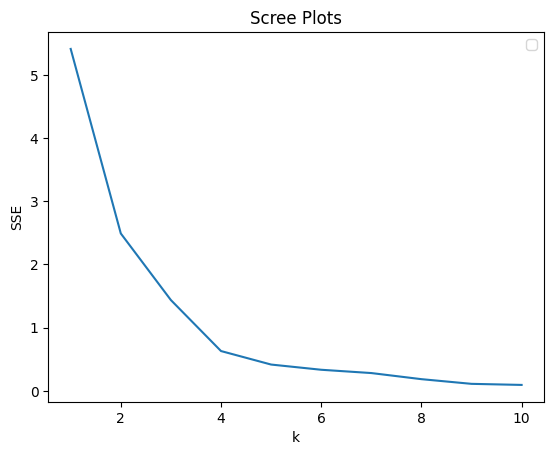

Group by          index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0         30.0  2782.600000  1664.320688   236.0  1494.0  2769.0  4307.5   
1          6.0  3783.333333   843.766476  2582.0  3194.0  4027.0  4375.5   
2        111.0  2768.540541  1665.488123    32.0  1205.0  2752.0  4112.0   
3          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
cluster                         ...                                            
0        5506.0   30.0  2020.0  ...                       0.048819  0.114776   
1        4656.0    6.0  2020.0  ...                       0.164503  0.225050   
2        5880.0  111.0  2020.0  ...                       

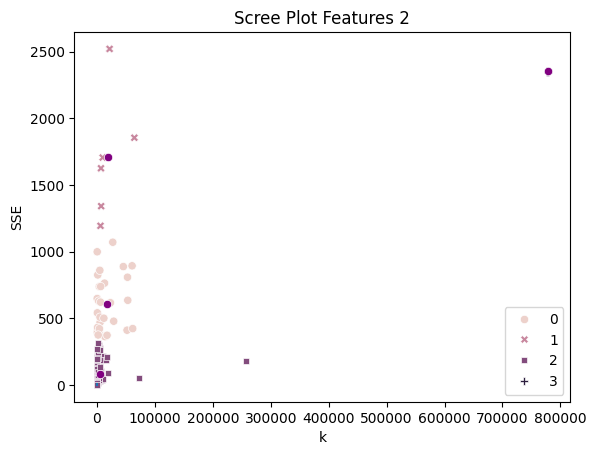

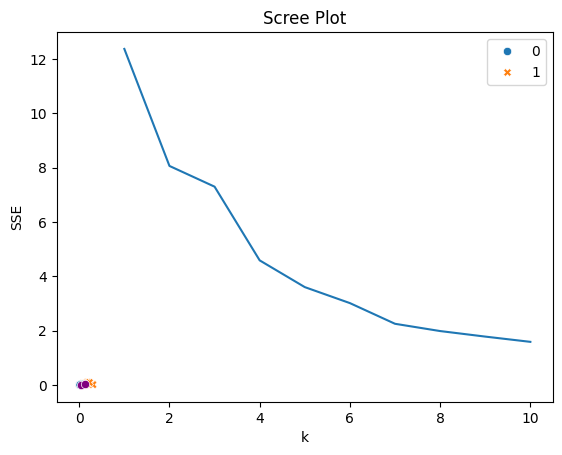

index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0         31.0  2512.903226  1789.866352   100.0   780.0  2514.0  3721.0   
1          2.0  4265.000000   312.541197  4044.0  4154.5  4265.0  4375.5   
2          4.0  3925.000000  1408.574220  2582.0  2837.0  3789.0  4877.0   
3        111.0  2854.918919  1618.183489    32.0  1545.0  2888.0  4231.0   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
cluster                         ...                                            
0        5438.0   31.0  2020.0  ...                       0.134663  0.303027   
1        4486.0    2.0  2020.0  ...                       0.213951  0.225050   
2        5540.0    4.0  2020.0  ...                       0.111880  0.116052   
3        5880.0  111.0  2020.0  ...                       0.050505  0.092044   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      31.0   212.689100  257.841988    18.297119   
1                       2.0  1523.989576  467.243215  1193.598730   
2                       4.0  2050.731339  451.391359  1625.156250   
3                     111.0   196.926833  267.788506     0.580129   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0          46.485917   135.459845   217.333791   998.966186  
1        1358.794153  1523.989576  1689.184999  1854.380422  
2        1685.593092  2028.685282  2393.823529  2520.398541  
3          14.880549    67.083417   295.296094  1341.058851  

[4 rows x 48 columns]

In [6]:
# Load in data
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


#------------Q1----------
# read in the data
df = pd.read_csv("/content/SIPRI Military Expenditure Database.csv")

print("var.dtypes:")
print(df.dtypes, '\n')

# Look at the first few rows of the data using .head()
df.head()

# Keep only year 2020
df = df[df["Year"] == 2020]

# Drop rows containing any missing values
df = df.dropna()

# Check how many countries
print(df.shape)
print("the df", df.head())

features = ["Spending (2020 USD)", "Spending per Capita"] #creating a feautres dataframe


#--------Q2--------

#scaling and calulating the min and max for features
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

#Scree
ks = np.arange(1, 11) # setting value KS

SSE = [
    KMeans(
        n_clusters=k,
        n_init="auto",
        random_state=0
    ).fit(X).inertia_
    for k in ks
] # calculating the SSE

sns.lineplot(x=ks, y=SSE) # showing the scree plot

plt.title("Scree Plots")# making a title
plt.xlabel("k") # making x value title
plt.ylabel("SSE") # making y value title
plt.legend()# creating legend
plt.show() # showing the plots


# Cluster Plot
model = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(X) # making the model
df["cluster"] = model.labels_ # putting the model.labels value in the df
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy() # creatingthe centers
ax = sns.scatterplot(
    data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster", style="cluster"
) #creating the scatterplot
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="purple", ax=ax)# plot the centers

print("Group by",df.groupby("cluster").describe())# look at clusters numerically

#-------------Q3-----------------
# Repeat for Percent of Government Spending and Percent of GDP


features_2 = ["Percent of Government Spending", "Percent of GDP"] # making the features variable


# calculating the min and max
unscaled = df.loc[:, features_2]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

#Scree
ks = np.arange(1, 11)# ks varible

SSE = [
    KMeans(
        n_clusters=k,
        n_init="auto",
        random_state=0
    ).fit(X).inertia_
    for k in ks
]# calculating the SSE

sns.lineplot(x=ks, y=SSE)# making a lineplot

plt.title("Scree Plot Features 2") # putting a title
plt.xlabel("k") # x axis label
plt.ylabel("SSE") # y axis label
plt.show() # show the plot


# Cluster Plot
model = KMeans(n_clusters=2, n_init="auto", random_state=0).fit(X)
df["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
ax = sns.scatterplot(
    data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="purple", ax=ax)


df.groupby("cluster").describe()



Factors = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
] # making the varaible for all of the features

# finding the min and max
unscaled = df.loc[:, Factors]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

X.agg(["min", "max"])

#Making the scree plot
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, n_init="auto", random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE)

plt.title("Scree Plot")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

model = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(X) # making the model
df["cluster"] = model.labels_ # setting the df cluser to have this value

df.groupby("cluster").describe() # showing the numbers of the cluster

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]